In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_csv('../data/cleaned/cleaned_retails.csv')

In [3]:
# check head and tails
df.head()


,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Normal / Other
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Normal / Other
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Normal / Other
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Normal / Other
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Normal / Other


In [4]:
display(df.tail())

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
536636,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,Normal / Other
536637,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,Normal / Other
536638,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,Normal / Other
536639,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,Normal / Other
536640,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,Normal / Other


## country Analysis 
  purpose: which country has higher no of orders.
   

# Question: 
    1. Which country has higher no  of orders?
    2. is the dataset orders has balance ?
    3. Which country has less no of orderes or need to focused?
    

In [5]:
country_value_count = df['country'].value_counts()

country_PCT = round(df['country'].value_counts(normalize=True) * 100 ,2)

pd.DataFrame({
    "Count" : country_value_count,
    "Percentage": country_PCT
}).head(10)

,Count,Percentage
country,,
United Kingdom,490300,91.36
Germany,9480,1.77
France,8541,1.59
Ireland,8184,1.53
Spain,2528,0.47
Netherlands,2371,0.44
Belgium,2069,0.39
Switzerland,1994,0.37
Portugal,1510,0.28


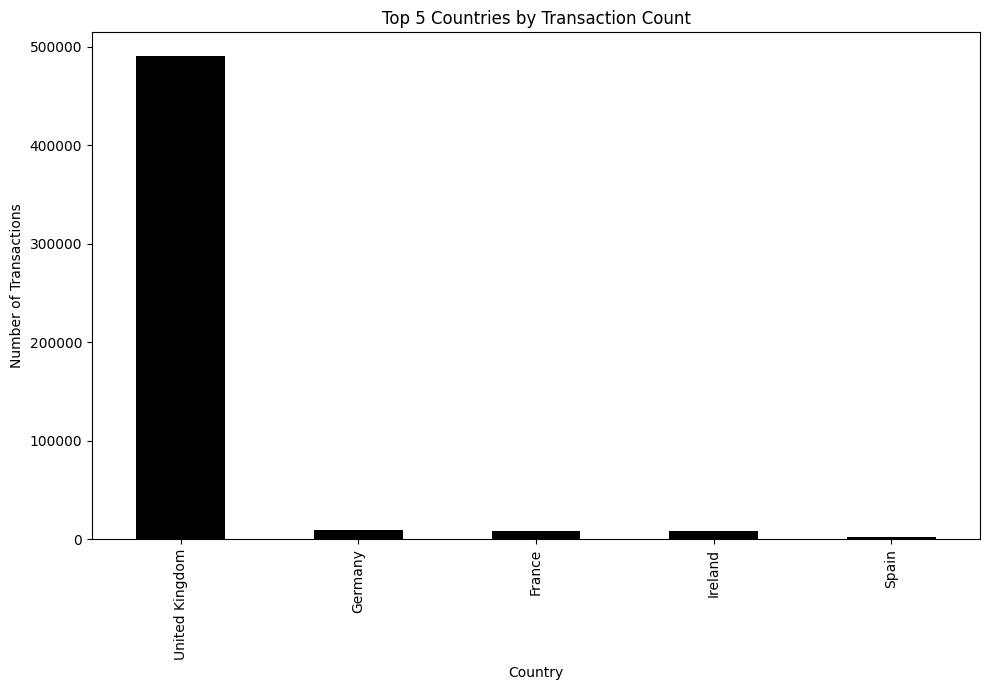

In [6]:
plt.figure(figsize=(10, 7))

country_value_count.sort_values(ascending=False).head(5).plot(
    kind='bar',
    color='black'
)

plt.title("Top 5 Countries by Transaction Count")
plt.ylabel("Number of Transactions")
plt.xlabel("Country")

plt.tight_layout()
plt.show()

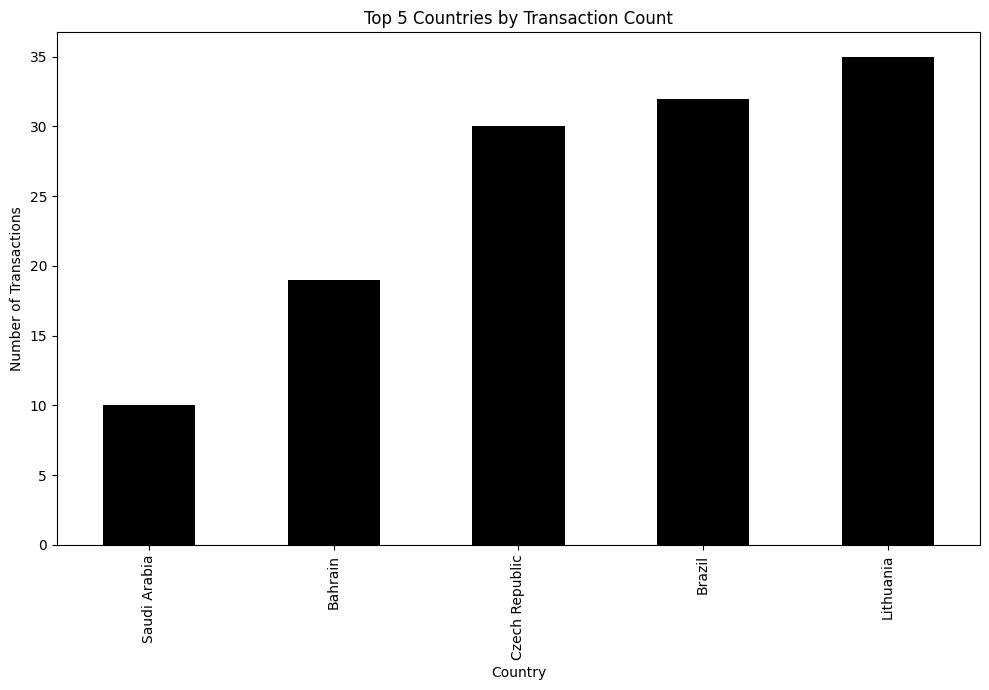

In [7]:
plt.figure(figsize=(10, 7))

country_value_count.sort_values(ascending=True).head(5).plot(
    kind='bar',
    color='black'
)

plt.title("Top 5 Countries by Transaction Count")
plt.ylabel("Number of Transactions")
plt.xlabel("Country")

plt.tight_layout()
plt.show()

In [11]:
# Analysis transaction_type

transaction_type_count = df['transaction_type'].value_counts()
transaction_pct =round(df['transaction_type'].value_counts() /len(df)* 100 ,2)

pd.DataFrame({
    'Count' : transaction_type_count,
    'Perecntage': transaction_pct
})

,Count,Perecntage
transaction_type,,
Normal / Other,527387,98.28
Cancellation,9251,1.72
Accounting Adjustment,3,0.00


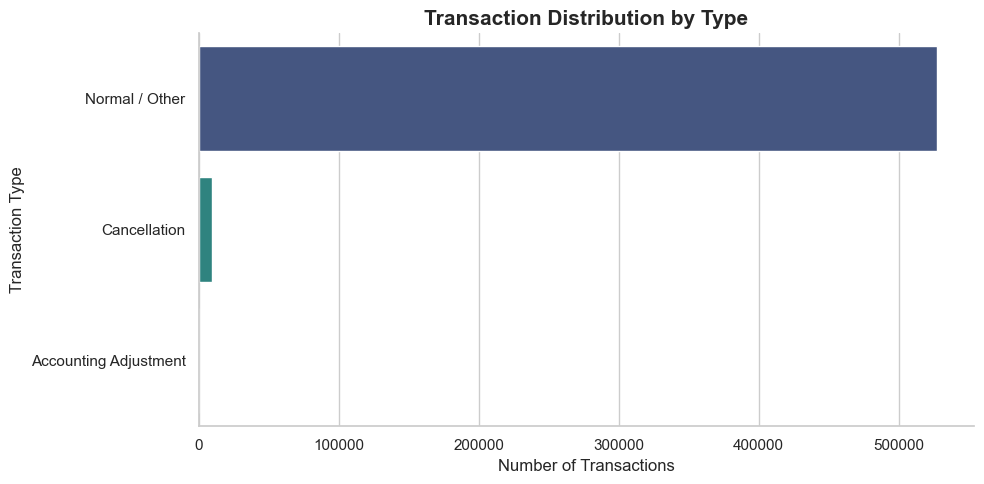

In [15]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=transaction_type_count.values,
    y=transaction_type_count.index,
    hue=transaction_type_count.index,
    palette='viridis',
    legend=False
)

plt.title('Transaction Distribution by Type',
          fontsize=15, fontweight='bold')

plt.xlabel('Number of Transactions')
plt.ylabel('Transaction Type')

sns.despine()
plt.tight_layout()
plt.show()

In [17]:
df['unitprice'].describe()

count    536641.000000
mean          4.632656
std          97.233118
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: unitprice, dtype: float64

In [20]:
print('Positive Unitpirce:', (df['unitprice'] > 0).sum())
print('Zero Unitpirce:', (df['unitprice'] == 0).sum())
print('Negative Unitpirce:', (df['unitprice'] < 0).sum())
print('Unique Unitpirce:', (df['unitprice'].unique()).sum())
print('Null Unitpirce:', (df['unitprice'].isna()).sum())

Positive Unitpirce: 534129
Zero Unitpirce: 2510
Negative Unitpirce: 2
Unique Unitpirce: 611388.391
Null Unitpirce: 0


In [21]:
df[df['unitprice'] == 0]

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
605,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,Normal / Other
1934,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,Normal / Other
1935,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,Normal / Other
1936,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,Normal / Other
1951,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,Normal / Other
...,...,...,...,...,...,...,...,...,...
531753,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom,Normal / Other
533259,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom,Normal / Other
533260,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom,Normal / Other
533309,581408,85175,NaN,20,2011-12-08 14:06:00,0.0,NaN,United Kingdom,Normal / Other


In [24]:
df[df['stockcode'] == '22139']['description'].value_counts(dropna=False)

description
RETROSPOT TEA SET CERAMIC 11 PC     980
NaN                                   4
amazon                                1
Name: count, dtype: int64

In [26]:
df[
    (df['stockcode'] == '22139') &
    (df['description'].isnull() | 
    (df['description'] == 'amazon'))
]

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
605,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,Normal / Other
6295,536942,22139,amazon,15,2010-12-03 12:08:00,0.0,NaN,United Kingdom,Normal / Other
7101,537011,22139,NaN,-5,2010-12-03 15:38:00,0.0,NaN,United Kingdom,Normal / Other
20014,538039,22139,NaN,7,2010-12-09 13:07:00,0.0,NaN,United Kingdom,Normal / Other
38876,539638,22139,NaN,1,2010-12-20 15:23:00,0.0,NaN,United Kingdom,Normal / Other


In [30]:
df.loc[
    df['stockcode'] == '22139',
    'description'
] = 'RETROSPOT TEA SET CERAMIC 11 PC'

df[df['stockcode'] == '22139']['description'].value_counts(dropna=False)

description
RETROSPOT TEA SET CERAMIC 11 PC    985
Name: count, dtype: int64

In [33]:
df[df['unitprice'] == 0].shape[0]

2510

In [34]:
zero_price = df[df['unitprice'] == 0]

zero_price[
    ['invoiceno', 'stockcode', 'description',
     'quantity', 'unitprice', 'customerid']
].head(20)

,invoiceno,stockcode,description,quantity,unitprice,customerid
605,536414,22139,RETROSPOT TEA SET CERAMIC 11 PC,56,0.0,NaN
1934,536545,21134,NaN,1,0.0,NaN
1935,536546,22145,NaN,1,0.0,NaN
1936,536547,37509,NaN,1,0.0,NaN
1951,536549,85226A,NaN,1,0.0,NaN
1952,536550,85044,NaN,1,0.0,NaN
1984,536552,20950,NaN,1,0.0,NaN
1985,536553,37461,NaN,3,0.0,NaN
1986,536554,84670,NaN,23,0.0,NaN
2362,536589,21777,NaN,-10,0.0,NaN


In [35]:
df[df['stockcode'] == '22139'][
    ['description', 'quantity', 'unitprice']
].value_counts()

description                      quantity  unitprice
RETROSPOT TEA SET CERAMIC 11 PC   3        4.95         363
                                  6        4.95         123
                                  1        4.95         116
                                  2        4.95          93
                                  1        10.79         90
                                  24       4.25          37
                                  12       4.95          28
                                  4        4.95          26
                                  2        10.79         20
                                  9        4.95          16
                                  5        4.95           8
                                  3        10.79          7
                                 -1        4.95           7
                                  5        10.79          5
                                 -3        4.95           5
                                  10       4.95

In [37]:
stock_median_price = (
    df[df['unitprice'] > 0]
    .groupby('stockcode')['unitprice']
    .median()
)

In [39]:
df[df['unitprice'] == 0]

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
605,536414,22139,RETROSPOT TEA SET CERAMIC 11 PC,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,Normal / Other
1934,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,Normal / Other
1935,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,Normal / Other
1936,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,Normal / Other
1951,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,Normal / Other
...,...,...,...,...,...,...,...,...,...
531753,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom,Normal / Other
533259,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom,Normal / Other
533260,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom,Normal / Other
533309,581408,85175,NaN,20,2011-12-08 14:06:00,0.0,NaN,United Kingdom,Normal / Other


In [42]:
df[df['stockcode']== '46000S']


,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
1999,536557,46000S,POLYESTER FILLER PAD 40x40cm,1,2010-12-01 14:41:00,1.45,17841.0,United Kingdom,Normal / Other
4796,536813,46000S,POLYESTER FILLER PAD 40x40cm,2,2010-12-02 16:59:00,1.45,15646.0,United Kingdom,Normal / Other
14534,537619,46000S,POLYESTER FILLER PAD 40x40cm,12,2010-12-07 13:53:00,1.45,13786.0,United Kingdom,Normal / Other
21977,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.00,NaN,United Kingdom,Normal / Other
32300,539118,46000S,POLYESTER FILLER PAD 40x40cm,25,2010-12-16 11:27:00,1.45,15563.0,United Kingdom,Normal / Other
...,...,...,...,...,...,...,...,...,...
515629,580295,46000S,POLYESTER FILLER PAD 40x40cm,2,2011-12-02 13:49:00,1.45,17841.0,United Kingdom,Normal / Other
517666,580438,46000S,POLYESTER FILLER PAD 40x40cm,10,2011-12-04 12:17:00,1.45,12827.0,United Kingdom,Normal / Other
526470,580958,46000S,POLYESTER FILLER PAD 40x40cm,1,2011-12-06 14:30:00,1.45,17266.0,United Kingdom,Normal / Other
533260,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.00,NaN,United Kingdom,Normal / Other


In [43]:
df[df['description'] == 'Dotcom sales']

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
21977,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.0,NaN,United Kingdom,Normal / Other
21978,538162,46000M,Dotcom sales,-100,2010-12-09 17:25:00,0.0,NaN,United Kingdom,Normal / Other


In [46]:
df.loc[df['stockcode'] == '46000S', 'quantity'].sum()

np.int64(2092)

In [54]:
df[df['stockcode'] == '46000S'][
    ['invoiceno', 'stockcode', 'description',
     'quantity', 'unitprice', 'invoicedate', 'transaction_type']
]

,invoiceno,stockcode,description,quantity,unitprice,invoicedate,transaction_type
1999,536557,46000S,POLYESTER FILLER PAD 40x40cm,1,1.45,2010-12-01 14:41:00,Normal / Other
4796,536813,46000S,POLYESTER FILLER PAD 40x40cm,2,1.45,2010-12-02 16:59:00,Normal / Other
14534,537619,46000S,POLYESTER FILLER PAD 40x40cm,12,1.45,2010-12-07 13:53:00,Normal / Other
21977,538161,46000S,Dotcom sales,-100,0.00,2010-12-09 17:25:00,Normal / Other
32300,539118,46000S,POLYESTER FILLER PAD 40x40cm,25,1.45,2010-12-16 11:27:00,Normal / Other
...,...,...,...,...,...,...,...
515629,580295,46000S,POLYESTER FILLER PAD 40x40cm,2,1.45,2011-12-02 13:49:00,Normal / Other
517666,580438,46000S,POLYESTER FILLER PAD 40x40cm,10,1.45,2011-12-04 12:17:00,Normal / Other
526470,580958,46000S,POLYESTER FILLER PAD 40x40cm,1,1.45,2011-12-06 14:30:00,Normal / Other
533260,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,0.00,2011-12-08 13:58:00,Normal / Other


In [57]:
df.loc[
    (df['quantity'] < 0) &
    (~df['invoiceno'].astype(str).str.startswith('C')),
    'transaction_type'
] = 'Cancellation'

In [58]:
df[df['stockcode'] == '46000S'][
    ['invoiceno', 'stockcode', 'description',
     'quantity', 'unitprice', 'invoicedate', 'transaction_type']
]

,invoiceno,stockcode,description,quantity,unitprice,invoicedate,transaction_type
1999,536557,46000S,POLYESTER FILLER PAD 40x40cm,1,1.45,2010-12-01 14:41:00,Normal / Other
4796,536813,46000S,POLYESTER FILLER PAD 40x40cm,2,1.45,2010-12-02 16:59:00,Normal / Other
14534,537619,46000S,POLYESTER FILLER PAD 40x40cm,12,1.45,2010-12-07 13:53:00,Normal / Other
21977,538161,46000S,Dotcom sales,-100,0.00,2010-12-09 17:25:00,Cancellation
32300,539118,46000S,POLYESTER FILLER PAD 40x40cm,25,1.45,2010-12-16 11:27:00,Normal / Other
...,...,...,...,...,...,...,...
515629,580295,46000S,POLYESTER FILLER PAD 40x40cm,2,1.45,2011-12-02 13:49:00,Normal / Other
517666,580438,46000S,POLYESTER FILLER PAD 40x40cm,10,1.45,2011-12-04 12:17:00,Normal / Other
526470,580958,46000S,POLYESTER FILLER PAD 40x40cm,1,1.45,2011-12-06 14:30:00,Normal / Other
533260,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,0.00,2011-12-08 13:58:00,Normal / Other


In [59]:
# eda 
df['unitprice'].describe()

count    536641.000000
mean          4.632656
std          97.233118
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: unitprice, dtype: float64

In [65]:
df[df['unitprice'] < 0][
    ['invoiceno', 'stockcode', 'description',
     'quantity', 'unitprice', 'customerid', 'transaction_type']
].head(10)

,invoiceno,stockcode,description,quantity,unitprice,customerid,transaction_type
297646,A563186,B,Adjust bad debt,1,-11062.06,NaN,Accounting Adjustment
297647,A563187,B,Adjust bad debt,1,-11062.06,NaN,Accounting Adjustment


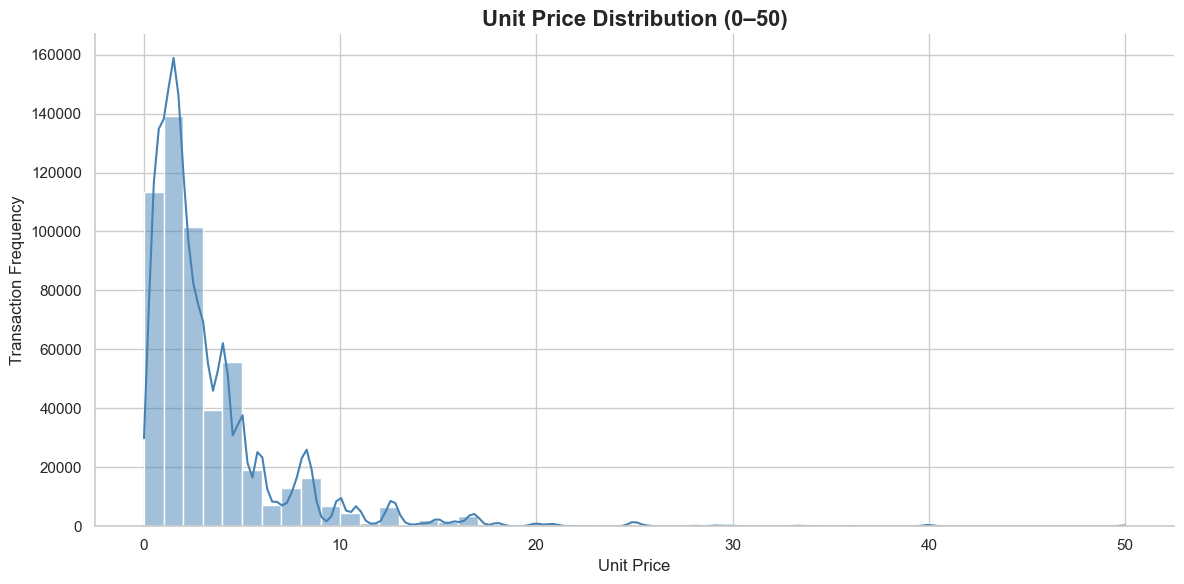

In [63]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df[df['unitprice'].between(0, 50)],
    x='unitprice',
    bins=50,
    kde=True,
    color='steelblue',
    edgecolor='white'
)

plt.title('Unit Price Distribution (0–50)',
          fontsize=16, fontweight='bold')

plt.xlabel('Unit Price')
plt.ylabel('Transaction Frequency')

sns.despine()
plt.tight_layout()
plt.show()

In [68]:
# ===================================
# unit price outlier check 
#====================================


# calculate outlier and iqr
Q1 = df['unitprice'].quantile(0.25)
Q3 = df['unitprice'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR


print("lower limit :", lower_limit)
print("upper limit: ", upper_limit)

# now EXtract outlier 

outliers = df[
    (df['unitprice'] < lower_limit)|
    (df['unitprice'] > upper_limit)
].copy()


# negative and positive outliers 
negative_outlier = outliers[
    outliers['unitprice'] < lower_limit
]

positive_outlier = outliers[
    outliers['unitprice'] > upper_limit ]


print("###########################")
print("Outlier Summery!")
print("Total Record:" , len(df))
print("Total Outliers: ", len(outliers))
print("Negative Outliers :", len(negative_outlier))
print("Positive Outliers: ", len(positive_outlier))
print("Outlier Percentage:", round(len(outliers) / len(df) * 100 , 2), "%")
      


lower limit : -3.0700000000000003
upper limit:  8.45
###########################
Outlier Summery!
Total Record: 536641
Total Outliers:  39450
Negative Outliers : 2
Positive Outliers:  39448
Outlier Percentage: 7.35 %


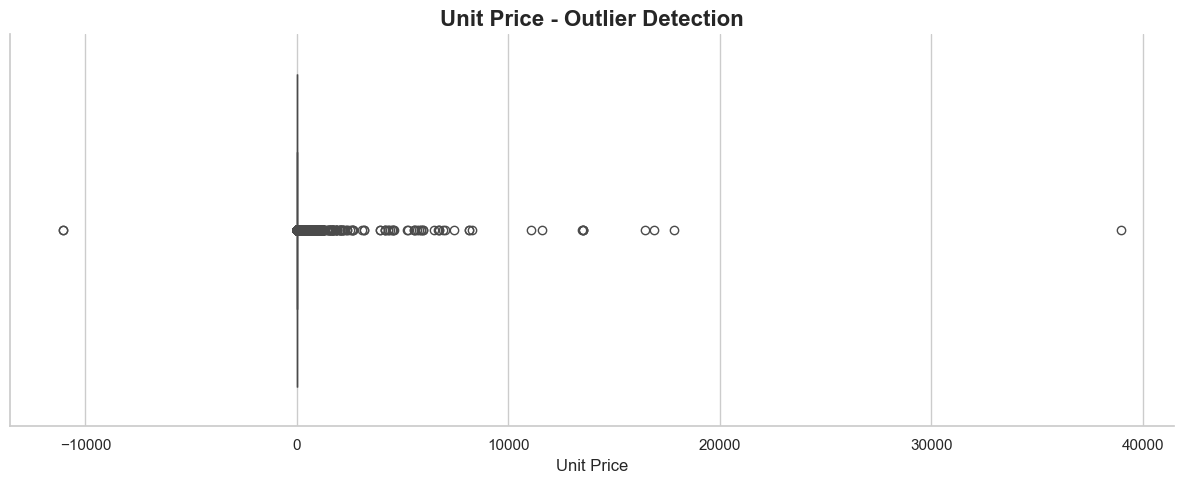

In [69]:
#  Visualize Outliers
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=df['unitprice'],
    color='steelblue',
    showfliers=True
)

plt.title(
    'Unit Price - Outlier Detection',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Unit Price', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

In [73]:
# higher price outlier 
display(
    positive_outlier.sort_values(
        by='unitprice',
        ascending=False
    )[['invoiceno', 'stockcode', 'description',
    'quantity', 'unitprice', 'customerid','transaction_type']].head()
)

,invoiceno,stockcode,description,quantity,unitprice,customerid,transaction_type
220826,C556445,M,Manual,-1,38970.00,15098.0,Cancellation
519497,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,NaN,Cancellation
43193,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,NaN,Cancellation
43194,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,NaN,Cancellation
14757,537632,AMAZONFEE,AMAZON FEE,1,13541.33,NaN,Normal / Other
